# Tesis NHANES – Parte final en local (Mac): TabPFN y secciones 14–16

Continuación del notebook `tesis_nhanes_corregido.ipynb`. Las secciones 1–13.3 se ejecutaron en Colab; aquí se cargan sus resultados y se completa lo que necesita TabPFN, sin GPU de NVIDIA.

- **Entrada** (carpeta Descargas): `train_modelo.csv`, `test_modelo.csv`, `modelo_svm.pkl`, `modelo_xgboost.pkl`, `modelo_random_forest (2).pkl`.
- **Random Forest:** `modelo_random_forest (2).pkl`, entrenado en Colab.
- **Salidas:** `~/tesis_nhanes_local/resultados/`.
- **Entorno:** kernel *Python (tesis_nhanes)*, con las mismas versiones que Colab (scikit-learn 1.6.1, xgboost 3.4.1, shap 0.52.0, tabpfn 9.0.0).

In [1]:
# Nota (macOS): el kernel "Python (tesis_nhanes)" arranca con DYLD_LIBRARY_PATH apuntando a torch/lib,
# para que XGBoost y PyTorch compartan la misma librería OpenMP (con dos copias el proceso se cae o se congela).
# --- Python ---
import os
import time
import random
import warnings
from pathlib import Path

# --- Datos ---
import numpy as np
import pandas as pd

# --- Visualización ---
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import seaborn as sns

# --- Estadística ---
import scipy.stats as stats
from scipy.stats import spearmanr

# --- Machine Learning ---
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV, cross_validate
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    roc_auc_score, roc_curve, average_precision_score, accuracy_score, precision_score,
    f1_score, brier_score_loss, confusion_matrix, classification_report, ConfusionMatrixDisplay,
)
from sklearn.ensemble import RandomForestClassifier
from tabpfn import TabPFNClassifier
from tabpfn.constants import ModelVersion

# --- Interpretabilidad ---
import shap
from tabpfn_extensions.interpretability.shapiq import get_tabpfn_imputation_explainer
from tabpfn_extensions.interpretability import shapiq_to_shap_explanation

import joblib

/Users/mcamilavt/tesis_nhanes_local/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DATA_DIR    = Path.home() / "Downloads"
RESULTS_DIR = Path.home() / "tesis_nhanes_local" / "resultados"
FIG_DIR     = RESULTS_DIR / "figuras"
FIG_DIR.mkdir(parents=True, exist_ok=True)

TARGET = "RESISTENCIA_INSULINA"
N_FOLDS, N_ITER_BUSQUEDA = 5, 50
cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
ALFA = 0.05

N_SHAP = 458
BUDGET_SHAP_TABPFN = 256
UMBRAL_IMPORTANCIA_ACUMULADA = 0.85
N_TOP_HEATMAP = 15
UMBRALES_DCA = np.round(np.arange(0.01, 1.00, 0.01), 2)
UMBRALES_DCA_TABLA = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60]
ETIQUETAS_CLASES = ["Sin RI", "Con RI"]

TABPFN_DEVICE = "mps"   # chip gráfico del Mac: ~8 veces más rápido que la CPU en la prueba de velocidad

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 250)
warnings.filterwarnings("ignore", category=FutureWarning)


def guardar_figura(nombre, dpi=300):
    plt.savefig(FIG_DIR / nombre, dpi=dpi, bbox_inches="tight")

In [3]:
train_modelo = pd.read_csv(DATA_DIR / "train_modelo.csv")
test_modelo = pd.read_csv(DATA_DIR / "test_modelo.csv")
X_train, y_train = train_modelo.drop(columns=[TARGET]), train_modelo[TARGET].astype(int)
X_test, y_test = test_modelo.drop(columns=[TARGET]), test_modelo[TARGET].astype(int)

svm = joblib.load(DATA_DIR / "modelo_svm.pkl")
xgb = joblib.load(DATA_DIR / "modelo_xgboost.pkl")
for nombre, modelo in [("SVM", svm), ("XGBoost", xgb)]:
    assert list(modelo.feature_names_in_) == list(X_train.columns), f"{nombre}: columnas distintas a los datos"

print(f"X_train: {X_train.shape} | X_test: {X_test.shape}")

X_train: (1828, 43) | X_test: (457, 43)


## 13.1 Random Forest (entrenado en Colab)

In [4]:
rf = joblib.load(DATA_DIR / "modelo_random_forest (2).pkl")
assert list(rf.feature_names_in_) == list(X_train.columns), "RF: columnas distintas a los datos"
print(f"Random Forest cargado: {rf.get_params()['n_estimators']} árboles, max_features={rf.get_params()['max_features']}")

Random Forest cargado: 200 árboles, max_features=sqrt


## 13.4 TabPFN-2.5

In [5]:
# Licencia/token: el token se lee de ~/tesis_nhanes_local/.tabpfn_token (nunca se escribe en el notebook)
ruta_token = Path.home() / "tesis_nhanes_local" / ".tabpfn_token"
if "TABPFN_TOKEN" not in os.environ and ruta_token.exists():
    os.environ["TABPFN_TOKEN"] = ruta_token.read_text().strip()

RUTA_MODELO_TABPFN = TabPFNClassifier.create_default_for_version(ModelVersion.V2_5).model_path
TABPFN_PARAMS = {"model_path": RUTA_MODELO_TABPFN, "n_estimators": 32, "balance_probabilities": True,
                 "random_state": SEED, "device": TABPFN_DEVICE}
# fit_with_cache (caché de ~6 GB en la memoria del chip gráfico) solo se usa para SHAP (sección 15.2):
# no cambia las predicciones, y activarla aquí agota la memoria en la validación cruzada.
print(f"Modelo TabPFN: {RUTA_MODELO_TABPFN} | dispositivo: {TABPFN_DEVICE}")

t0 = time.time()
modelo_tabpfn = TabPFNClassifier(**TABPFN_PARAMS)
modelo_tabpfn.fit(X_train, y_train)
# No se guarda con joblib: con fit_mode="fit_with_cache" el archivo incluye la caché y ocupa > 6 GB.
# Se reproduce reentrenando con TABPFN_PARAMS (determinista con random_state); las probabilidades se guardan en la sección 14.
print(f"TabPFN entrenado en {time.time() - t0:.0f} s")

Modelo TabPFN: /Users/mcamilavt/Library/Caches/tabpfn/tabpfn-v2.5-classifier-v2.5_default.ckpt | dispositivo: mps


TabPFN entrenado en 0 s


## 14. Evaluación en el conjunto de prueba
Todas las métricas se calculan con una sola función. Umbral de clasificación: 0.5 (`predict`).


=== CLASIFICACIÓN (Random Forest) ===
              precision    recall  f1-score   support

      Sin RI       0.80      0.84      0.82       267
      Con RI       0.76      0.71      0.73       190

    accuracy                           0.79       457
   macro avg       0.78      0.77      0.78       457
weighted avg       0.78      0.79      0.78       457



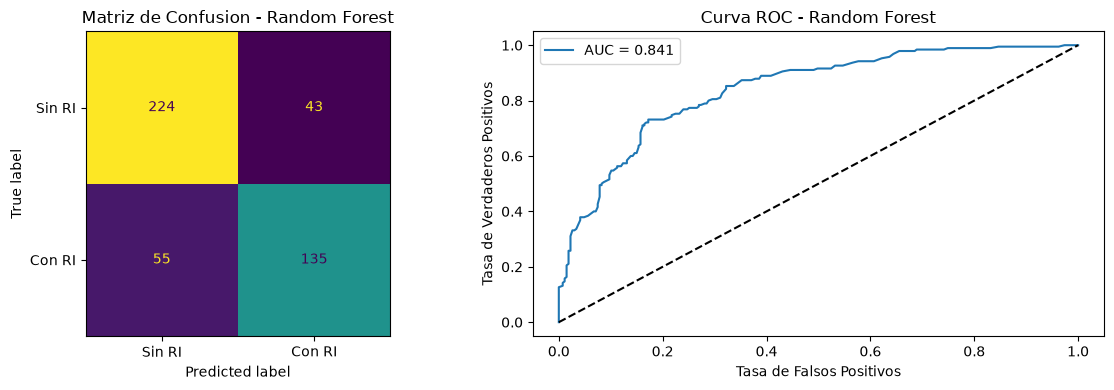


=== CLASIFICACIÓN (SVM) ===
              precision    recall  f1-score   support

      Sin RI       0.79      0.80      0.80       267
      Con RI       0.71      0.71      0.71       190

    accuracy                           0.76       457
   macro avg       0.75      0.75      0.75       457
weighted avg       0.76      0.76      0.76       457



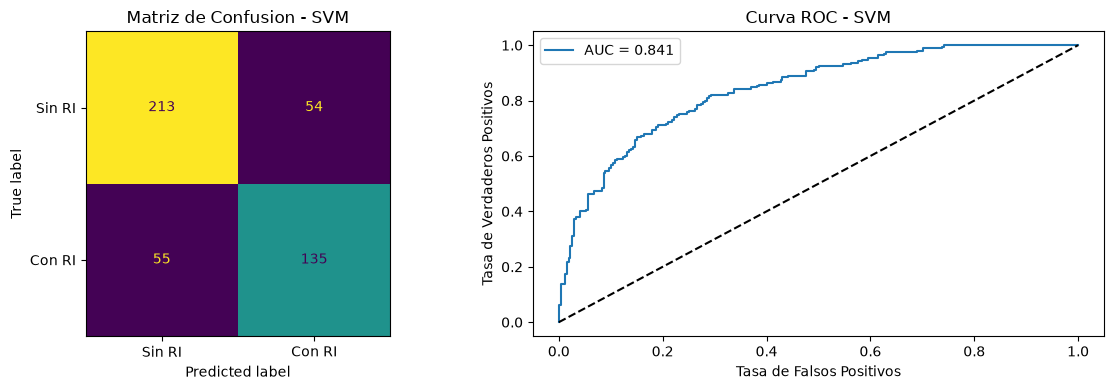


=== CLASIFICACIÓN (XGBoost) ===
              precision    recall  f1-score   support

      Sin RI       0.82      0.77      0.79       267
      Con RI       0.70      0.76      0.73       190

    accuracy                           0.77       457
   macro avg       0.76      0.76      0.76       457
weighted avg       0.77      0.77      0.77       457



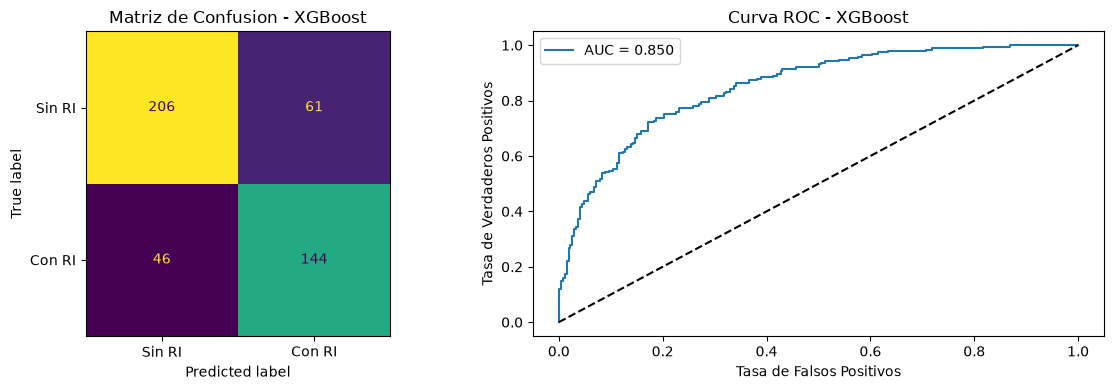


=== CLASIFICACIÓN (TabPFN) ===
              precision    recall  f1-score   support

      Sin RI       0.83      0.78      0.80       267
      Con RI       0.71      0.77      0.74       190

    accuracy                           0.77       457
   macro avg       0.77      0.77      0.77       457
weighted avg       0.78      0.77      0.78       457



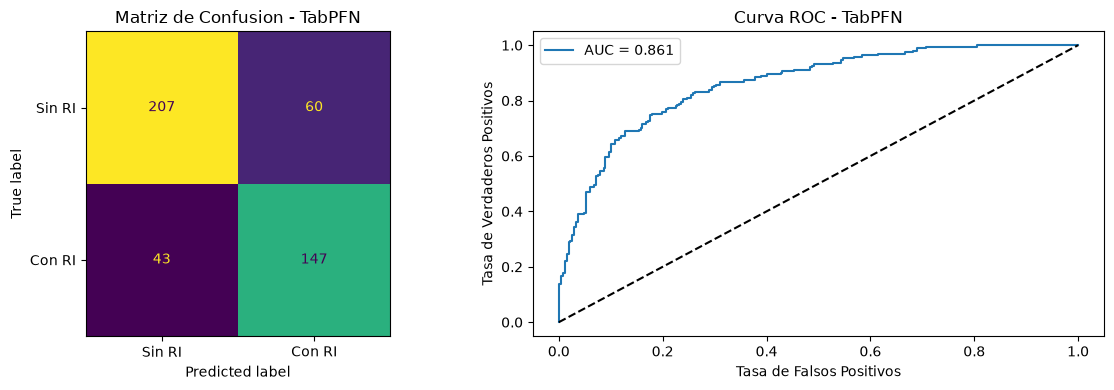

In [6]:
MODELOS = {"Random Forest": rf, "SVM": svm, "XGBoost": xgb, "TabPFN": modelo_tabpfn}


def calcular_metricas(y_true, y_pred, y_prob):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return {"AUC-ROC": roc_auc_score(y_true, y_prob), "PR-AUC": average_precision_score(y_true, y_prob),
            "Sensibilidad": tp / (tp + fn), "Especificidad": tn / (tn + fp),
            "Accuracy": accuracy_score(y_true, y_pred), "Precisión": precision_score(y_true, y_pred),
            "F1": f1_score(y_true, y_pred), "Brier": brier_score_loss(y_true, y_prob)}


def evaluar_en_test(nombre, modelo, X, y, archivo_figura, dpi=300):
    """Reporte de clasificación, matriz de confusión y curva ROC en test. Devuelve predicciones y métricas."""
    y_pred = modelo.predict(X)
    y_prob = modelo.predict_proba(X)[:, 1]
    metricas = calcular_metricas(y, y_pred, y_prob)

    print(f"\n=== CLASIFICACIÓN ({nombre}) ===")
    print(classification_report(y, y_pred, target_names=ETIQUETAS_CLASES))

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    ConfusionMatrixDisplay(confusion_matrix(y, y_pred), display_labels=ETIQUETAS_CLASES).plot(ax=axes[0], colorbar=False)
    axes[0].set_title(f"Matriz de Confusion - {nombre}")
    fpr, tpr, _ = roc_curve(y, y_prob)
    axes[1].plot(fpr, tpr, label=f"AUC = {metricas['AUC-ROC']:.3f}")
    axes[1].plot([0, 1], [0, 1], "k--")
    axes[1].set_xlabel("Tasa de Falsos Positivos")
    axes[1].set_ylabel("Tasa de Verdaderos Positivos")
    axes[1].set_title(f"Curva ROC - {nombre}")
    axes[1].legend()
    plt.tight_layout()
    guardar_figura(archivo_figura, dpi=dpi)
    plt.show()
    return {"y_pred": y_pred, "y_prob": y_prob, "metricas": metricas}


ARCHIVOS_RESULTADOS = {"Random Forest": "rf_resultados.png", "SVM": "svm_resultados.png",
                       "XGBoost": "xgb_resultados.png", "TabPFN": "tabpfn_resultados.png"}
resultados_test = {nombre: evaluar_en_test(nombre, modelo, X_test, y_test, ARCHIVOS_RESULTADOS[nombre])
                   for nombre, modelo in MODELOS.items()}

In [7]:
tabla_metricas_test = pd.DataFrame({m: r["metricas"] for m, r in resultados_test.items()}).T.round(4)
tabla_metricas_test.to_csv(RESULTS_DIR / "tabla_metricas_test.csv")
tabla_metricas_test

# Probabilidades predichas en test de los 4 modelos (permiten recalcular métricas, ROC y DCA sin reentrenar)
pd.DataFrame({"y_test": y_test.to_numpy(), **{m: r["y_prob"] for m, r in resultados_test.items()}}).to_csv(RESULTS_DIR / "probabilidades_test.csv", index=False)
tabla_metricas_test

,AUC-ROC,PR-AUC,Sensibilidad,Especificidad,Accuracy,Precisión,F1,Brier
Random Forest,0.8408,0.7912,0.7105,0.8390,0.7856,0.7584,0.7337,0.1608
SVM,0.8409,0.7920,0.7105,0.7978,0.7615,0.7143,0.7124,0.1599
XGBoost,0.8496,0.8037,0.7579,0.7715,0.7659,0.7024,0.7291,0.1582
TabPFN,0.8606,0.8188,0.7737,0.7753,0.7746,0.7101,0.7406,0.1527


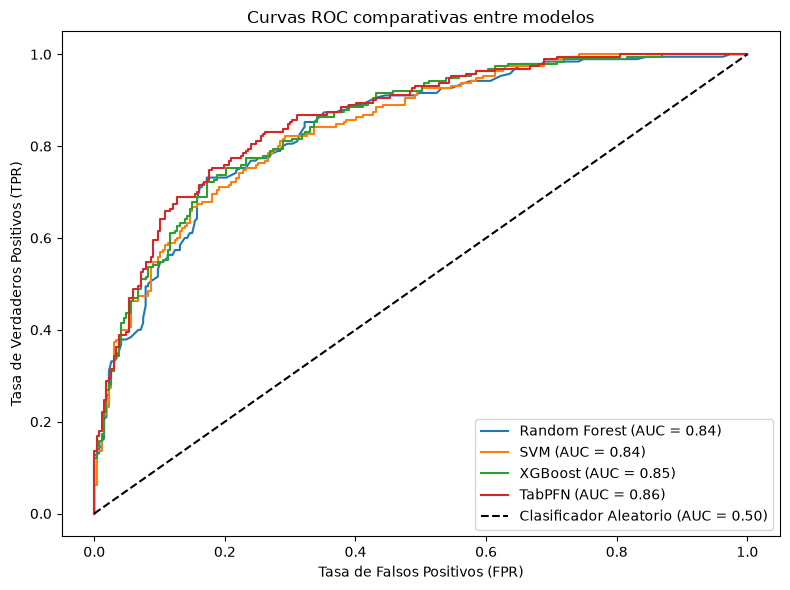

In [8]:
plt.figure(figsize=(8, 6))
for nombre, r in resultados_test.items():
    fpr, tpr, _ = roc_curve(y_test, r["y_prob"])
    plt.plot(fpr, tpr, label=f"{nombre} (AUC = {r['metricas']['AUC-ROC']:.2f})")
plt.plot([0, 1], [0, 1], "k--", label="Clasificador Aleatorio (AUC = 0.50)")
plt.title("Curvas ROC comparativas entre modelos")
plt.xlabel("Tasa de Falsos Positivos (FPR)")
plt.ylabel("Tasa de Verdaderos Positivos (TPR)")
plt.legend(loc="lower right")
plt.tight_layout()
guardar_figura("comparacion_roc_modelos.png")
plt.show()

### 14.1 Métricas en validación cruzada (conjunto de entrenamiento)

In [9]:
modelos_cv = {"RF": rf, "SVM": svm, "XGBoost": xgb, "TabPFN": modelo_tabpfn}
metricas_cv = {"Accuracy": "accuracy", "Precisión": "precision", "Recall": "recall",
               "F1-Score": "f1", "AUC-ROC": "roc_auc"}

filas = []
for nombre, modelo in modelos_cv.items():
    print(f"Evaluando {nombre}...")
    res = cross_validate(clone(modelo), X_train, y_train, cv=cv, scoring=metricas_cv, n_jobs=1, error_score="raise")
    fila = {("", "Modelo"): nombre}
    for metrica in metricas_cv:
        valores = res[f"test_{metrica}"]
        media, sd = valores.mean(), valores.std(ddof=1)
        fila[(metrica, "Promedio")], fila[(metrica, "Sd")], fila[(metrica, "CV")] = round(media, 4), round(sd, 4), round(sd / media, 4)
    filas.append(fila)

tabla_metricas = pd.DataFrame(filas)
tabla_metricas.columns = pd.MultiIndex.from_tuples(tabla_metricas.columns)
tabla_metricas = tabla_metricas.set_index(("", "Modelo"))
tabla_metricas.index.name = "Modelo"
tabla_metricas.to_csv(RESULTS_DIR / "tabla_metricas_cv.csv")
tabla_metricas

Evaluando RF...


Evaluando SVM...


Evaluando XGBoost...


Evaluando TabPFN...


Accuracy                 Precisión                   Recall                 F1-Score                  AUC-ROC                
        Promedio      Sd      CV  Promedio      Sd      CV Promedio      Sd      CV Promedio      Sd      CV Promedio      Sd      CV
Modelo                                                                                                                               
RF        0.7708  0.0223  0.0289    0.7587  0.0422  0.0556   0.6628  0.0189  0.0285   0.7071  0.0236  0.0333   0.8508  0.0215  0.0253
SVM       0.7642  0.0185  0.0243    0.7046  0.0290  0.0411   0.7506  0.0232  0.0310   0.7265  0.0178  0.0244   0.8468  0.0150  0.0177
XGBoost   0.7817  0.0289  0.0370    0.7243  0.0400  0.0552   0.7717  0.0263  0.0341   0.7470  0.0303  0.0406   0.8581  0.0179  0.0209
TabPFN    0.7856  0.0140  0.0178    0.7248  0.0182  0.0251   0.7835  0.0227  0.0290   0.7528  0.0154  0.0205   0.8653  0.0107  0.0124

## 15. Interpretabilidad

### 15.1 Importancia nativa de XGBoost

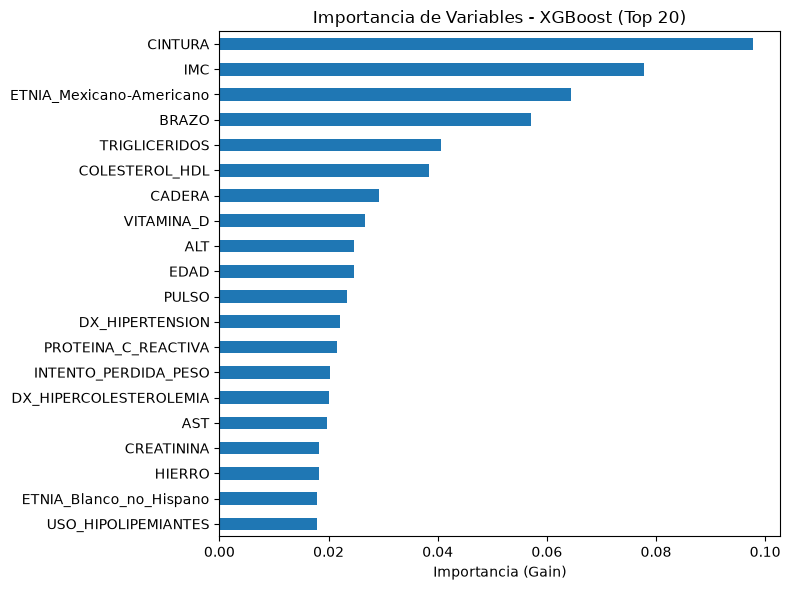

In [10]:
importancias_xgb = pd.Series(xgb.feature_importances_, index=X_train.columns).sort_values(ascending=False).head(20)

fig, ax = plt.subplots(figsize=(8, 6))
importancias_xgb.sort_values().plot(kind="barh", ax=ax)
ax.set_title("Importancia de Variables - XGBoost (Top 20)")
ax.set_xlabel("Importancia (Gain)")
plt.tight_layout()
guardar_figura("xgb_importancia.png")
plt.show()

### 15.2 Valores SHAP

Los valores SHAP se calcularon sobre una submuestra aleatoria del conjunto de entrenamiento (n = 458, semilla 42), de modo que el conjunto de prueba no interviene en la interpretación ni en la selección de variables y se reserva para la evaluación final. Para Random Forest y XGBoost se usó TreeExplainer. Para interpretar TabPFN-2.5, cuya arquitectura no se basa en árboles de decisión, se usó el paquete shapiq (Muschalik et al., 2024) con el adaptador de imputación basado en características (feature-removal imputation) sobre la probabilidad predicha de la clase positiva, con un presupuesto de 256 evaluaciones por observación. Se eligió este adaptador en lugar del método de reentrenamiento exacto (remove-and-recontextualize; Rundel et al., 2024) porque este último no reutiliza la caché del modelo y resultó computacionalmente impracticable para el número de variables del estudio.

✏️ *Texto actualizado en la versión corregida: trasladar al documento de tesis.*

In [11]:
X_shap = X_train.sample(n=min(N_SHAP, len(X_train)), random_state=SEED)


def shap_clase_positiva(valores):
    """Extrae los valores SHAP de la clase 1 (el formato cambia según la versión de shap)."""
    if isinstance(valores, list):
        return valores[1]
    return valores[:, :, 1] if valores.ndim == 3 else valores


shap_rf = shap_clase_positiva(shap.TreeExplainer(rf).shap_values(X_shap))
shap_xgb = shap_clase_positiva(shap.TreeExplainer(xgb).shap_values(X_shap))

# Copia de TabPFN con caché (mismos parámetros) para acelerar SHAP; antes se libera la memoria del chip gráfico
import gc, torch
gc.collect()
if torch.backends.mps.is_available():
    torch.mps.empty_cache()
tabpfn_shap = TabPFNClassifier(**TABPFN_PARAMS, fit_mode="fit_with_cache")
tabpfn_shap.fit(X_train, y_train)

explainer_tabpfn = get_tabpfn_imputation_explainer(model=tabpfn_shap, data=X_train.values, class_index=1,
                                                   index="SV", max_order=1, random_state=SEED)  # valores de Shapley clásicos
t0 = time.time()
shap_tabpfn = shapiq_to_shap_explanation(explainer_tabpfn, X_shap.values, budget=BUDGET_SHAP_TABPFN,
                                         feature_names=list(X_shap.columns)).values
print(f"SHAP TabPFN: {time.time() - t0:.1f} s para {len(X_shap)} observaciones")

# Liberar la copia con caché (~6 GB en el chip gráfico) antes de seguir entrenando TabPFN
del tabpfn_shap, explainer_tabpfn
gc.collect()
if torch.backends.mps.is_available():
    torch.mps.empty_cache()

SHAP_POR_MODELO = {"Random Forest": shap_rf, "XGBoost": shap_xgb, "TabPFN": shap_tabpfn}

/Users/mcamilavt/tesis_nhanes_local/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but TabPFNClassifier was fitted with feature names
  warnings.warn(


/Users/mcamilavt/tesis_nhanes_local/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but TabPFNClassifier was fitted with feature names
  warnings.warn(


/Users/mcamilavt/tesis_nhanes_local/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but TabPFNClassifier was fitted with feature names
  warnings.warn(


/Users/mcamilavt/tesis_nhanes_local/.venv/lib/python3.12/site-packages/shapiq/approximator/regression/oddshap.py:572: RuntimeWarning: divide by zero encountered in matmul
  parity_matrix = np.remainder(coalitions_used.astype(np.float64) @ interaction_masks.T, 2.0)
/Users/mcamilavt/tesis_nhanes_local/.venv/lib/python3.12/site-packages/shapiq/approximator/regression/oddshap.py:572: RuntimeWarning: overflow encountered in matmul
  parity_matrix = np.remainder(coalitions_used.astype(np.float64) @ interaction_masks.T, 2.0)
/Users/mcamilavt/tesis_nhanes_local/.venv/lib/python3.12/site-packages/shapiq/approximator/regression/oddshap.py:572: RuntimeWarning: invalid value encountered in matmul
  parity_matrix = np.remainder(coalitions_used.astype(np.float64) @ interaction_masks.T, 2.0)
/Users/mcamilavt/tesis_nhanes_local/.venv/lib/python3.12/site-packages/shapiq/approximator/regression/oddshap.py:786: RuntimeWarning: divide by zero encountered in matmul
  sv_values[1:] = -2.0 * (masks.T @ share

/Users/mcamilavt/tesis_nhanes_local/.venv/lib/python3.12/site-packages/shapiq/approximator/regression/oddshap.py:572: RuntimeWarning: divide by zero encountered in matmul
  parity_matrix = np.remainder(coalitions_used.astype(np.float64) @ interaction_masks.T, 2.0)
/Users/mcamilavt/tesis_nhanes_local/.venv/lib/python3.12/site-packages/shapiq/approximator/regression/oddshap.py:572: RuntimeWarning: overflow encountered in matmul
  parity_matrix = np.remainder(coalitions_used.astype(np.float64) @ interaction_masks.T, 2.0)
/Users/mcamilavt/tesis_nhanes_local/.venv/lib/python3.12/site-packages/shapiq/approximator/regression/oddshap.py:572: RuntimeWarning: invalid value encountered in matmul
  parity_matrix = np.remainder(coalitions_used.astype(np.float64) @ interaction_masks.T, 2.0)
/Users/mcamilavt/tesis_nhanes_local/.venv/lib/python3.12/site-packages/shapiq/approximator/regression/oddshap.py:786: RuntimeWarning: divide by zero encountered in matmul
  sv_values[1:] = -2.0 * (masks.T @ share

/Users/mcamilavt/tesis_nhanes_local/.venv/lib/python3.12/site-packages/shapiq/approximator/regression/oddshap.py:572: RuntimeWarning: divide by zero encountered in matmul
  parity_matrix = np.remainder(coalitions_used.astype(np.float64) @ interaction_masks.T, 2.0)
/Users/mcamilavt/tesis_nhanes_local/.venv/lib/python3.12/site-packages/shapiq/approximator/regression/oddshap.py:572: RuntimeWarning: overflow encountered in matmul
  parity_matrix = np.remainder(coalitions_used.astype(np.float64) @ interaction_masks.T, 2.0)
/Users/mcamilavt/tesis_nhanes_local/.venv/lib/python3.12/site-packages/shapiq/approximator/regression/oddshap.py:572: RuntimeWarning: invalid value encountered in matmul
  parity_matrix = np.remainder(coalitions_used.astype(np.float64) @ interaction_masks.T, 2.0)
/Users/mcamilavt/tesis_nhanes_local/.venv/lib/python3.12/site-packages/shapiq/approximator/regression/oddshap.py:786: RuntimeWarning: divide by zero encountered in matmul
  sv_values[1:] = -2.0 * (masks.T @ share

... (452 outputs left out)

/Users/mcamilavt/tesis_nhanes_local/.venv/lib/python3.12/site-packages/shapiq/approximator/regression/oddshap.py:572: RuntimeWarning: divide by zero encountered in matmul
  parity_matrix = np.remainder(coalitions_used.astype(np.float64) @ interaction_masks.T, 2.0)
/Users/mcamilavt/tesis_nhanes_local/.venv/lib/python3.12/site-packages/shapiq/approximator/regression/oddshap.py:572: RuntimeWarning: overflow encountered in matmul
  parity_matrix = np.remainder(coalitions_used.astype(np.float64) @ interaction_masks.T, 2.0)
/Users/mcamilavt/tesis_nhanes_local/.venv/lib/python3.12/site-packages/shapiq/approximator/regression/oddshap.py:572: RuntimeWarning: invalid value encountered in matmul
  parity_matrix = np.remainder(coalitions_used.astype(np.float64) @ interaction_masks.T, 2.0)
/Users/mcamilavt/tesis_nhanes_local/.venv/lib/python3.12/site-packages/shapiq/approximator/regression/oddshap.py:786: RuntimeWarning: divide by zero encountered in matmul
  sv_values[1:] = -2.0 * (masks.T @ share

/Users/mcamilavt/tesis_nhanes_local/.venv/lib/python3.12/site-packages/shapiq/approximator/regression/oddshap.py:572: RuntimeWarning: divide by zero encountered in matmul
  parity_matrix = np.remainder(coalitions_used.astype(np.float64) @ interaction_masks.T, 2.0)
/Users/mcamilavt/tesis_nhanes_local/.venv/lib/python3.12/site-packages/shapiq/approximator/regression/oddshap.py:572: RuntimeWarning: overflow encountered in matmul
  parity_matrix = np.remainder(coalitions_used.astype(np.float64) @ interaction_masks.T, 2.0)
/Users/mcamilavt/tesis_nhanes_local/.venv/lib/python3.12/site-packages/shapiq/approximator/regression/oddshap.py:572: RuntimeWarning: invalid value encountered in matmul
  parity_matrix = np.remainder(coalitions_used.astype(np.float64) @ interaction_masks.T, 2.0)
/Users/mcamilavt/tesis_nhanes_local/.venv/lib/python3.12/site-packages/shapiq/approximator/regression/oddshap.py:786: RuntimeWarning: divide by zero encountered in matmul
  sv_values[1:] = -2.0 * (masks.T @ share

/Users/mcamilavt/tesis_nhanes_local/.venv/lib/python3.12/site-packages/shapiq/approximator/regression/oddshap.py:572: RuntimeWarning: divide by zero encountered in matmul
  parity_matrix = np.remainder(coalitions_used.astype(np.float64) @ interaction_masks.T, 2.0)
/Users/mcamilavt/tesis_nhanes_local/.venv/lib/python3.12/site-packages/shapiq/approximator/regression/oddshap.py:572: RuntimeWarning: overflow encountered in matmul
  parity_matrix = np.remainder(coalitions_used.astype(np.float64) @ interaction_masks.T, 2.0)
/Users/mcamilavt/tesis_nhanes_local/.venv/lib/python3.12/site-packages/shapiq/approximator/regression/oddshap.py:572: RuntimeWarning: invalid value encountered in matmul
  parity_matrix = np.remainder(coalitions_used.astype(np.float64) @ interaction_masks.T, 2.0)
/Users/mcamilavt/tesis_nhanes_local/.venv/lib/python3.12/site-packages/shapiq/approximator/regression/oddshap.py:786: RuntimeWarning: divide by zero encountered in matmul
  sv_values[1:] = -2.0 * (masks.T @ share

SHAP TabPFN: 3132.8 s para 458 observaciones


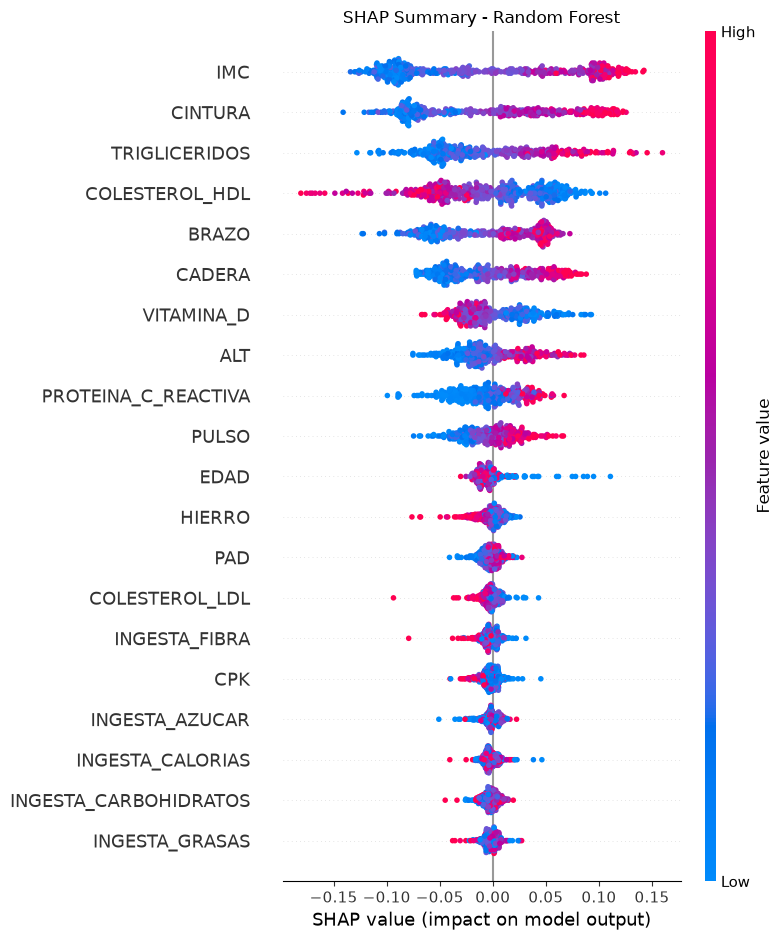

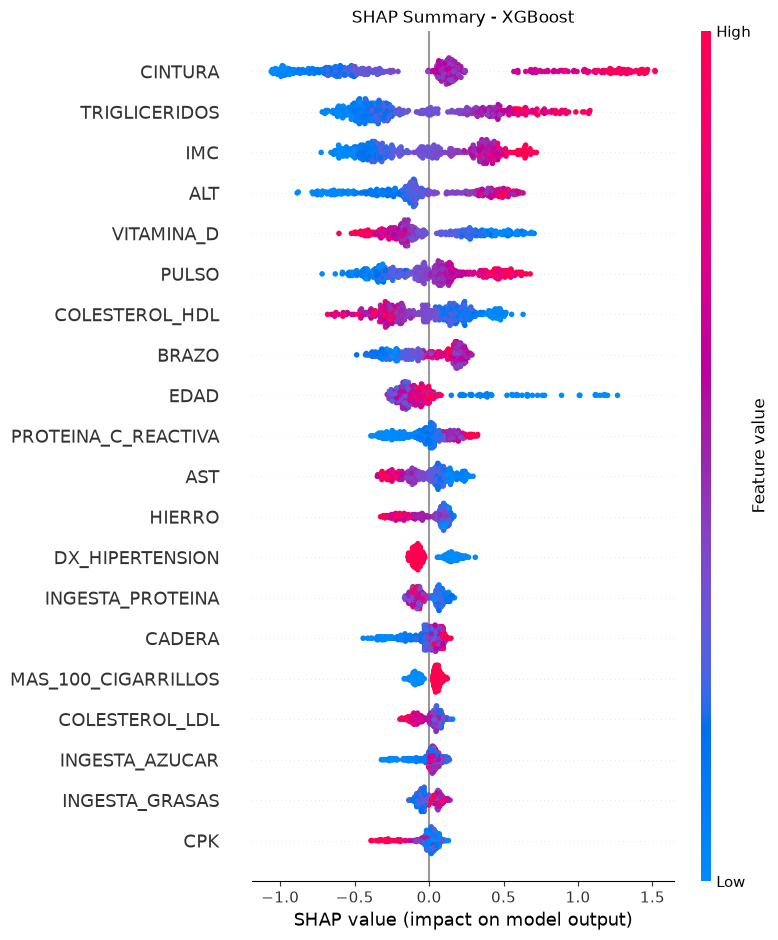

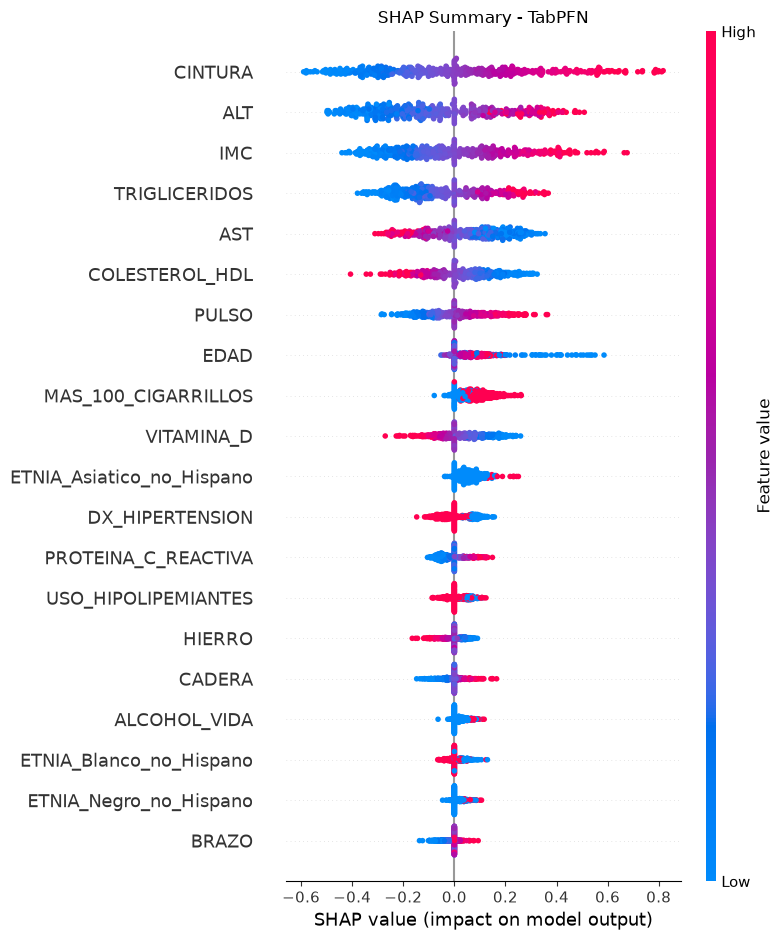

In [12]:
for (nombre, valores), archivo in zip(SHAP_POR_MODELO.items(), ["shap_summary_rf.png", "shap_summary_xgb.png",
                                                                 "shap_summary_tabpfn.png"]):
    plt.figure()
    shap.summary_plot(valores, X_shap, show=False)
    plt.title(f"SHAP Summary - {nombre}")
    plt.tight_layout()
    guardar_figura(archivo, dpi=150)
    plt.show()

In [13]:
def importancia_shap(valores, columna):
    return (pd.DataFrame({"variable": X_shap.columns, columna: np.abs(valores).mean(axis=0)})
            .sort_values(columna, ascending=False).reset_index(drop=True))


importancia_rf = importancia_shap(shap_rf, "mean_abs_shap_rf")
importancia_xgb = importancia_shap(shap_xgb, "mean_abs_shap_xgb")
importancia_tabpfn = importancia_shap(shap_tabpfn, "mean_abs_shap_tabpfn")

comparacion = (importancia_rf.merge(importancia_xgb, on="variable", how="outer")
                             .merge(importancia_tabpfn, on="variable", how="outer"))
for m in ["rf", "xgb", "tabpfn"]:
    comparacion[f"ranking_{m}"] = comparacion[f"mean_abs_shap_{m}"].rank(ascending=False)
comparacion["ranking_promedio"] = comparacion[["ranking_rf", "ranking_xgb", "ranking_tabpfn"]].mean(axis=1)
comparacion = comparacion.sort_values("ranking_promedio").reset_index(drop=True)
comparacion.to_csv(RESULTS_DIR / "comparacion_importancia_shap.csv", index=False)

for a, b in [("rf", "xgb"), ("rf", "tabpfn"), ("xgb", "tabpfn")]:
    rho, p_valor = spearmanr(comparacion[f"ranking_{a}"], comparacion[f"ranking_{b}"])
    print(f"Spearman {a.upper()} vs {b.upper()}: rho = {rho:.4f}, p = {p_valor:.4g}")

top10 = {m: set(imp.head(10)["variable"]) for m, imp in
         [("rf", importancia_rf), ("xgb", importancia_xgb), ("tabpfn", importancia_tabpfn)]}
print(f"\nTop 10 común RF y XGBoost: {sorted(top10['rf'] & top10['xgb'])}")
print(f"Top 10 común a los tres modelos: {sorted(top10['rf'] & top10['xgb'] & top10['tabpfn'])}")
comparacion

Spearman RF vs XGB: rho = 0.8363, p = 2.926e-12
Spearman RF vs TABPFN: rho = 0.3029, p = 0.04832
Spearman XGB vs TABPFN: rho = 0.5718, p = 6.187e-05

Top 10 común RF y XGBoost: ['ALT', 'BRAZO', 'CINTURA', 'COLESTEROL_HDL', 'IMC', 'PROTEINA_C_REACTIVA', 'PULSO', 'TRIGLICERIDOS', 'VITAMINA_D']
Top 10 común a los tres modelos: ['ALT', 'CINTURA', 'COLESTEROL_HDL', 'IMC', 'PULSO', 'TRIGLICERIDOS', 'VITAMINA_D']


,variable,mean_abs_shap_rf,mean_abs_shap_xgb,mean_abs_shap_tabpfn,ranking_rf,ranking_xgb,ranking_tabpfn,ranking_promedio
0,CINTURA,0.062081,0.590886,0.260906,2.0,1.0,1.0,1.333333
1,IMC,0.076640,0.359269,0.194019,1.0,3.0,3.0,2.333333
2,TRIGLICERIDOS,0.046692,0.424803,0.156439,3.0,2.0,4.0,3.000000
3,ALT,0.024676,0.318350,0.218407,8.0,4.0,2.0,4.666667
4,COLESTEROL_HDL,0.045330,0.236541,0.114561,4.0,7.0,6.0,5.666667
5,VITAMINA_D,0.025156,0.268475,0.079504,7.0,5.0,10.0,7.333333
6,PULSO,0.018863,0.250438,0.098347,10.0,6.0,7.0,7.666667
7,EDAD,0.009845,0.173217,0.082739,11.0,9.0,8.0,9.333333
8,PROTEINA_C_REACTIVA,0.023197,0.126449,0.044815,9.0,10.0,13.0,10.666667
9,BRAZO,0.041912,0.183979,0.020961,5.0,8.0,20.0,11.000000


### 15.3 Análisis de parsimonia de características

Con el propósito de identificar el subconjunto mínimo de variables capaz de preservar la mayor parte de la capacidad predictiva, se calculó, de forma independiente para Random Forest, XGBoost y TabPFN, la importancia acumulada de las variables a partir de sus valores SHAP en el conjunto de entrenamiento. Para cada modelo, la importancia media absoluta de SHAP de cada variable se normalizó como proporción del total de importancia de ese modelo y las variables se ordenaron de mayor a menor. Sobre esta ordenación se calculó la importancia acumulada y se identificó el número mínimo de variables necesario para alcanzar el 85 % de la importancia acumulada.

✏️ *Texto actualizado en la versión corregida: trasladar al documento de tesis.*

In [14]:
def analizar_parsimonia(df_importancia, columna_shap, nombre_modelo, umbral=UMBRAL_IMPORTANCIA_ACUMULADA):
    """Número mínimo de variables que acumulan `umbral` de la importancia SHAP total."""
    df = df_importancia.copy()
    df["proporcion"] = df[columna_shap] / df[columna_shap].sum()
    df = df.sort_values("proporcion", ascending=False).reset_index(drop=True)
    df["importancia_acumulada"] = df["proporcion"].cumsum()
    df["n_variables"] = np.arange(1, len(df) + 1)
    n_variables = df.loc[df["importancia_acumulada"] >= umbral, "n_variables"].iloc[0]
    variables = df.iloc[:n_variables]["variable"].tolist()
    print(f"{nombre_modelo}: {n_variables} variables para el {umbral:.0%} → {variables}")
    return df, n_variables, variables


tabla_rf, n_rf, variables_rf = analizar_parsimonia(importancia_rf, "mean_abs_shap_rf", "Random Forest")
tabla_xgb, n_xgb, variables_xgb = analizar_parsimonia(importancia_xgb, "mean_abs_shap_xgb", "XGBoost")
tabla_tabpfn, n_tabpfn, variables_tabpfn = analizar_parsimonia(importancia_tabpfn, "mean_abs_shap_tabpfn", "TabPFN")

n_predictores = X_train.shape[1]
resumen_parsimonia = pd.DataFrame({
    "Modelo": ["Random Forest", "XGBoost", "TabPFN"],
    f"n_variables_{UMBRAL_IMPORTANCIA_ACUMULADA:.0%}": [n_rf, n_xgb, n_tabpfn],
    f"% del total ({n_predictores} var)": [round(n / n_predictores * 100, 1) for n in [n_rf, n_xgb, n_tabpfn]],
})
resumen_parsimonia

Random Forest: 18 variables para el 85% → ['IMC', 'CINTURA', 'TRIGLICERIDOS', 'COLESTEROL_HDL', 'BRAZO', 'CADERA', 'VITAMINA_D', 'ALT', 'PROTEINA_C_REACTIVA', 'PULSO', 'EDAD', 'HIERRO', 'PAD', 'COLESTEROL_LDL', 'INGESTA_FIBRA', 'CPK', 'INGESTA_AZUCAR', 'INGESTA_CALORIAS']
XGBoost: 18 variables para el 85% → ['CINTURA', 'TRIGLICERIDOS', 'IMC', 'ALT', 'VITAMINA_D', 'PULSO', 'COLESTEROL_HDL', 'BRAZO', 'EDAD', 'PROTEINA_C_REACTIVA', 'AST', 'HIERRO', 'DX_HIPERTENSION', 'INGESTA_PROTEINA', 'CADERA', 'MAS_100_CIGARRILLOS', 'COLESTEROL_LDL', 'INGESTA_AZUCAR']
TabPFN: 16 variables para el 85% → ['CINTURA', 'ALT', 'IMC', 'TRIGLICERIDOS', 'AST', 'COLESTEROL_HDL', 'PULSO', 'EDAD', 'MAS_100_CIGARRILLOS', 'VITAMINA_D', 'ETNIA_Asiatico_no_Hispano', 'DX_HIPERTENSION', 'PROTEINA_C_REACTIVA', 'USO_HIPOLIPEMIANTES', 'HIERRO', 'CADERA']


,Modelo,n_variables_85%,% del total (43 var)
0,Random Forest,18,41.9
1,XGBoost,18,41.9
2,TabPFN,16,37.2


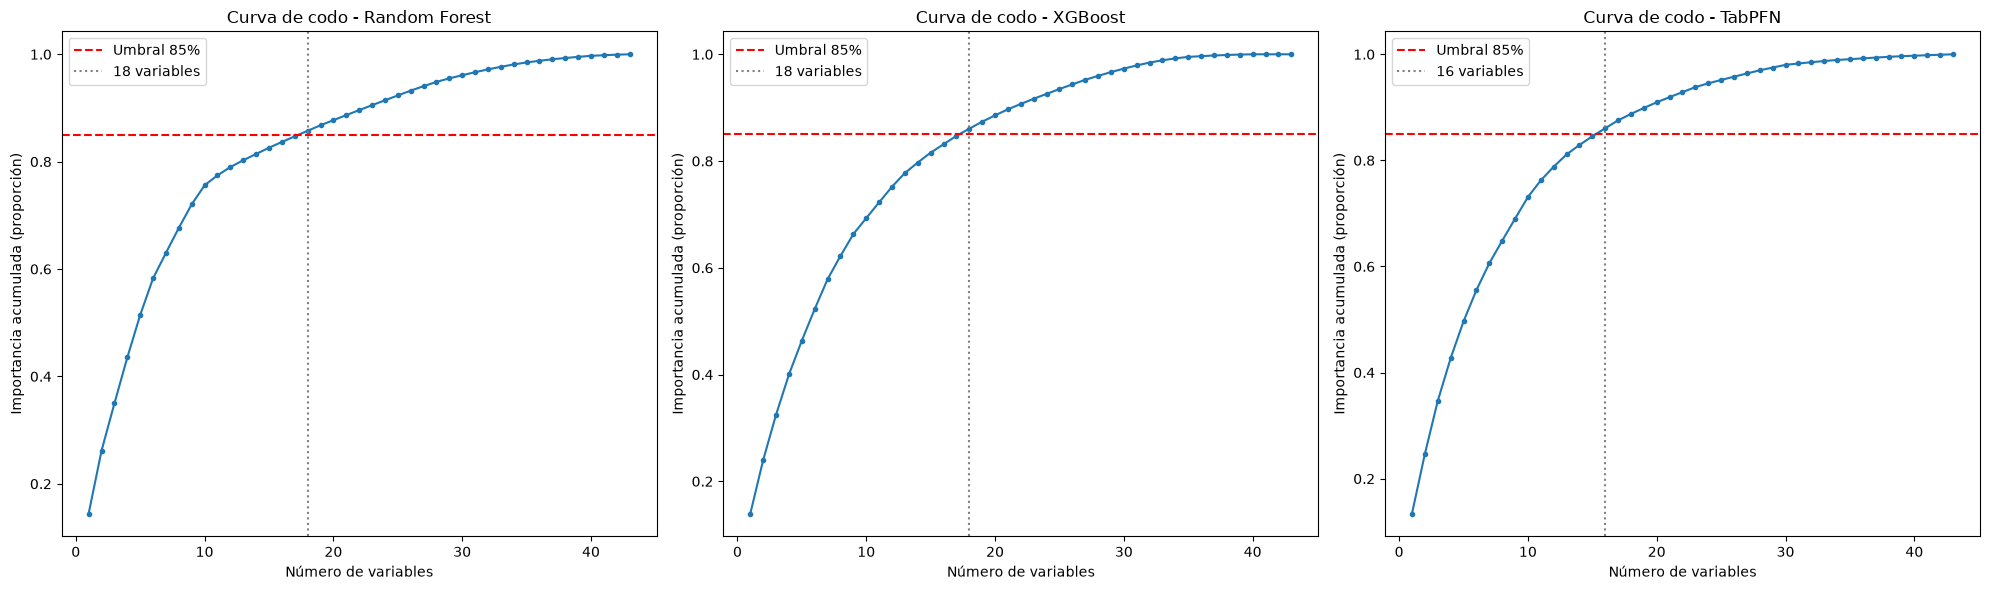

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, tabla, nombre, n_var in [(axes[0], tabla_rf, "Random Forest", n_rf),
                                 (axes[1], tabla_xgb, "XGBoost", n_xgb),
                                 (axes[2], tabla_tabpfn, "TabPFN", n_tabpfn)]:
    ax.plot(tabla["n_variables"], tabla["importancia_acumulada"], marker="o", markersize=3)
    ax.axhline(y=UMBRAL_IMPORTANCIA_ACUMULADA, color="red", linestyle="--", label=f"Umbral {UMBRAL_IMPORTANCIA_ACUMULADA:.0%}")
    ax.axvline(x=n_var, color="gray", linestyle=":", label=f"{n_var} variables")
    ax.set_xlabel("Número de variables")
    ax.set_ylabel("Importancia acumulada (proporción)")
    ax.set_title(f"Curva de codo - {nombre}")
    ax.legend()
plt.tight_layout()
guardar_figura("elbow_curve_3modelos.png", dpi=150)
plt.show()

### 15.4 Análisis de consenso

Las variables de consenso se definieron como la intersección de los tres subconjuntos parsimoniosos (Random Forest, XGBoost y TabPFN), es decir, las variables necesarias para alcanzar el 85 % de la importancia SHAP en los tres modelos a la vez. Como la selección usa solo datos de entrenamiento, la comparación posterior en el conjunto de prueba (prueba de DeLong) es una evaluación independiente.

✏️ *Texto actualizado en la versión corregida: trasladar al documento de tesis.*

In [16]:
variables_consenso = [v for v in variables_rf if v in set(variables_xgb) & set(variables_tabpfn)]
assert variables_consenso, "La intersección de los tres subconjuntos parsimoniosos está vacía"

consenso_pct = [round(len(variables_consenso) / n * 100, 1) for n in [n_rf, n_xgb, n_tabpfn]]
print(f"Variables de consenso ({len(variables_consenso)}): {variables_consenso}")
print(f"% de las variables de cada modelo incluidas en el consenso (RF, XGB, TabPFN): {consenso_pct}")

X_train_consenso = X_train[variables_consenso]
X_test_consenso = X_test[variables_consenso]

Variables de consenso (11): ['IMC', 'CINTURA', 'TRIGLICERIDOS', 'COLESTEROL_HDL', 'CADERA', 'VITAMINA_D', 'ALT', 'PROTEINA_C_REACTIVA', 'PULSO', 'EDAD', 'HIERRO']
% de las variables de cada modelo incluidas en el consenso (RF, XGB, TabPFN): [np.float64(61.1), np.float64(61.1), np.float64(68.8)]


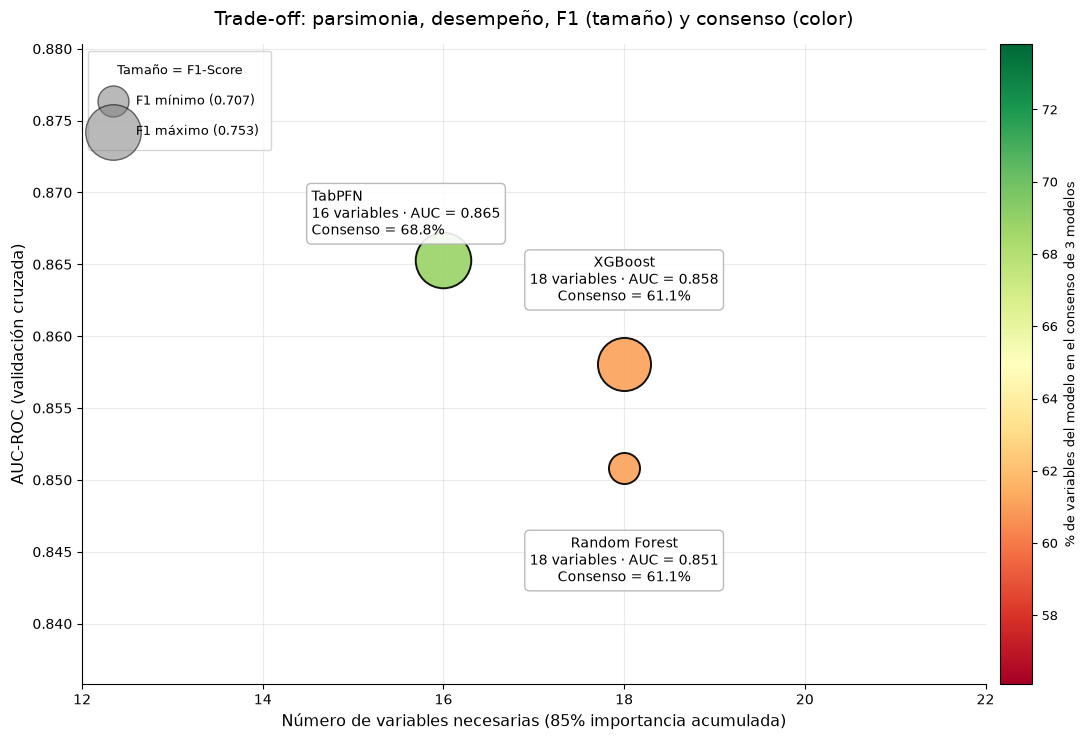

In [17]:
# Trade-off parsimonia / desempeño. Todos los valores salen de las tablas calculadas arriba.
modelos_tradeoff = ["Random Forest", "XGBoost", "TabPFN"]
filas_cv = ["RF", "XGBoost", "TabPFN"]
auc_tradeoff = tabla_metricas.loc[filas_cv, ("AUC-ROC", "Promedio")].tolist()
f1_tradeoff = tabla_metricas.loc[filas_cv, ("F1-Score", "Promedio")].tolist()
n_vars = [n_rf, n_xgb, n_tabpfn]

tam_min, tam_max = 500, 1600
f1_min, f1_max = min(f1_tradeoff), max(f1_tradeoff)


def tamano_por_f1(f):
    return tam_min + (f - f1_min) / ((f1_max - f1_min) or 1) * (tam_max - tam_min)


cmap = plt.get_cmap("RdYlGn")
norm = mcolors.Normalize(vmin=min(consenso_pct) - 5, vmax=max(consenso_pct) + 5)
offsets = {"Random Forest": (0, -48, "center", "top"), "XGBoost": (0, 42, "center", "bottom"),
           "TabPFN": (-95, 15, "left", "bottom")}

fig, ax = plt.subplots(figsize=(11, 7.5))
for m, n, a, f, cp in zip(modelos_tradeoff, n_vars, auc_tradeoff, f1_tradeoff, consenso_pct):
    ax.scatter(n, a, s=tamano_por_f1(f), color=cmap(norm(cp)), edgecolor="black", linewidth=1.4, zorder=3, alpha=0.92)
    dx, dy, ha, va = offsets[m]
    ax.annotate(f"{m}\n{n} variables · AUC = {a:.3f}\nConsenso = {cp:.1f}%", (n, a), textcoords="offset points",
                xytext=(dx, dy), fontsize=10, ha=ha, va=va,
                bbox=dict(boxstyle="round,pad=0.35", fc="white", ec="0.7", alpha=0.9))
ax.set_xlabel("Número de variables necesarias (85% importancia acumulada)", fontsize=11.5)
ax.set_ylabel("AUC-ROC (validación cruzada)", fontsize=11.5)
ax.set_title("Trade-off: parsimonia, desempeño, F1 (tamaño) y consenso (color)", fontsize=13.5, pad=14)
ax.set_xlim(min(n_vars) - 4, max(n_vars) + 4)
ax.set_ylim(min(auc_tradeoff) - 0.015, max(auc_tradeoff) + 0.015)
ax.grid(alpha=0.25, zorder=0)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
sm = cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])
cbar = plt.colorbar(sm, ax=ax, pad=0.015, fraction=0.05)
cbar.set_label("% de variables del modelo en el consenso de 3 modelos", fontsize=9.5)
cbar.ax.tick_params(labelsize=9)
leyenda = [ax.scatter([], [], s=tamano_por_f1(f), color="gray", edgecolor="black", alpha=0.55, label=etiqueta)
           for f, etiqueta in [(f1_min, f"F1 mínimo ({f1_min:.3f})"), (f1_max, f"F1 máximo ({f1_max:.3f})")]]
ax.legend(handles=leyenda, loc="upper left", fontsize=9, title="Tamaño = F1-Score", title_fontsize=9.5,
          frameon=True, borderpad=1, labelspacing=1.3)
plt.tight_layout()
guardar_figura("tradeoff_enriquecido.png", dpi=150)
plt.show()

In [18]:
scoring_consenso = {"acc": "accuracy", "auc": "roc_auc", "f1": "f1"}

filas = []
for nombre, modelo in modelos_cv.items():
    for etiqueta, X_cv in [(f"Completo ({X_train.shape[1]} var)", X_train),
                           (f"Consenso ({len(variables_consenso)} var)", X_train_consenso)]:
        print(f"Evaluando {nombre} - {etiqueta}...")
        res = cross_validate(clone(modelo), X_cv, y_train, cv=cv, scoring=scoring_consenso, n_jobs=1, error_score="raise")
        filas.append({"Modelo": nombre, "Conjunto de variables": etiqueta,
                      "AUC-ROC": round(res["test_auc"].mean(), 4), "Accuracy": round(res["test_acc"].mean(), 4),
                      "F1-Score": round(res["test_f1"].mean(), 4)})

tabla_consenso = pd.DataFrame(filas)
tabla_consenso.to_csv(RESULTS_DIR / "tabla_comparacion_consenso.csv", index=False)

pivote = tabla_consenso.pivot(index="Modelo", columns="Conjunto de variables", values="AUC-ROC")
pivote["Diferencia AUC-ROC"] = pivote.iloc[:, 0] - pivote.iloc[:, 1]   # completo - consenso
pivote

Evaluando RF - Completo (43 var)...


Evaluando RF - Consenso (11 var)...


Evaluando SVM - Completo (43 var)...


Evaluando SVM - Consenso (11 var)...


Evaluando XGBoost - Completo (43 var)...


Evaluando XGBoost - Consenso (11 var)...


Evaluando TabPFN - Completo (43 var)...


TabPFNMPSOutOfMemoryError: MPS out of memory with 366 test samples.

This is issue is usually caused by one of the following two reasons:

1) Large test set — split into batches:

    predictions = []
    for i in range(0, len(X_test), 100):
        pred = model.predict_proba(X_test[i:i + 100])
        predictions.append(pred)
    predictions = np.vstack(predictions)

   Only with fit_mode='fit_with_cache', test rows are chunked
   automatically — lower the TABPFN_MAX_BATCHED_TEST_ROWS
   environment variable (currently 32768) to
   reduce peak memory without changing your code.

2) Large training set — batching won't help.
   Subsample your training data; see https://docs.priorlabs.ai
   for further guidance.

Your sizes: 1,462 train / 366 test samples, 43 features.
Not sure which? If model.predict_proba(X_test[:1]) also fails, it's (2).

Original error: MPS backend out of memory (MPS allocated: 7.57 GiB, other allocations: 4.72 MiB, max allowed: 7.47 GiB). Tried to allocate 6.38 MiB 

### 15.5 Prueba de DeLong: modelo completo vs. modelo de consenso (conjunto de prueba)

In [ ]:
def _compute_midrank(x):
    J = np.argsort(x)
    Z = x[J]
    N = len(x)
    T = np.zeros(N, dtype=float)
    i = 0
    while i < N:
        j = i
        while j < N and Z[j] == Z[i]:
            j += 1
        T[i:j] = 0.5 * (i + j - 1) + 1
        i = j
    T2 = np.empty(N, dtype=float)
    T2[J] = T
    return T2


def delong_test(y_true, pred_a, pred_b):
    """Prueba de DeLong pareada para comparar dos curvas ROC sobre las mismas observaciones."""
    y_true = np.asarray(y_true)
    order = (-y_true).argsort()
    preds = np.vstack([pred_a[order], pred_b[order]])
    m = int(y_true.sum())   # positivos
    n = len(y_true) - m     # negativos

    tx_rank = np.array([_compute_midrank(p[:m]) for p in preds])
    ty_rank = np.array([_compute_midrank(p[m:]) for p in preds])
    tz_rank = np.array([_compute_midrank(p) for p in preds])

    aucs = tz_rank[:, :m].sum(axis=1) / (m * n) - (m + 1.0) / (2.0 * n)
    v01 = (tz_rank[:, :m] - tx_rank) / n
    v10 = 1.0 - (tz_rank[:, m:] - ty_rank) / m
    delongcov = np.cov(v01) / m + np.cov(v10) / n

    l = np.array([1, -1])
    diff_auc = l @ aucs
    z = diff_auc / np.sqrt(l @ delongcov @ l)
    p = 2 * (1 - stats.norm.cdf(abs(z)))
    return diff_auc, z, p, aucs[0], aucs[1]

In [ ]:
resultados_delong = []
for nombre, modelo in modelos_cv.items():
    print(f"Entrenando {nombre} con las variables de consenso...")
    pred_completo = modelo.predict_proba(X_test)[:, 1]
    pred_consenso = clone(modelo).fit(X_train_consenso, y_train).predict_proba(X_test_consenso)[:, 1]
    diff, z, p, auc_completo, auc_consenso = delong_test(y_test.values, pred_completo, pred_consenso)
    resultados_delong.append({"Modelo": nombre, "AUC completo": round(auc_completo, 4),
                              "AUC consenso": round(auc_consenso, 4), "Diferencia": round(diff, 4),
                              "z": round(z, 3), "p-valor": round(p, 4),
                              "Significativo (α=0.05)": "Sí" if p < ALFA else "No"})

tabla_delong = pd.DataFrame(resultados_delong)
tabla_delong.to_csv(RESULTS_DIR / "tabla_delong.csv", index=False)
tabla_delong

### 15.6 Mapa de calor de importancia relativa

In [ ]:
prop = pd.DataFrame({"Random Forest": tabla_rf.set_index("variable")["proporcion"],
                     "XGBoost": tabla_xgb.set_index("variable")["proporcion"],
                     "TabPFN": tabla_tabpfn.set_index("variable")["proporcion"]})
prop = prop.loc[prop.mean(axis=1).sort_values(ascending=False).index[:N_TOP_HEATMAP]]

fig, ax = plt.subplots(figsize=(8, 0.5 * N_TOP_HEATMAP + 2.5))
sns.heatmap(prop, annot=True, fmt=".2f", cmap="YlGnBu", linewidths=0.5, linecolor="gray",
            cbar_kws={"label": "Importancia relativa (proporción SHAP)"}, ax=ax)
ax.set_title("Mapa de calor - Importancia de variables por modelo (SHAP)", fontsize=13, fontweight="bold")
ax.set_xlabel("Modelo")
ax.set_ylabel("Variable predictora")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
guardar_figura("heatmap_importancia_modelos.png")
plt.show()

## 16. Curvas de decisión clínica (Decision Curve Analysis) y calibración

El análisis de curvas de decisión (Vickers & Elkin, 2006) evalúa la **utilidad clínica** de cada modelo: si usarlo para decidir a quién intervenir (p. ej., solicitar una evaluación metabólica completa o iniciar una intervención de estilo de vida) produce más beneficio que las estrategias por defecto de intervenir a todos o a nadie.

Para cada probabilidad umbral *pₜ* (la probabilidad de RI a partir de la cual el clínico intervendría):

$$\text{Beneficio neto} = \frac{VP}{n} - \frac{FP}{n}\cdot\frac{p_t}{1-p_t}$$

El factor *pₜ/(1−pₜ)* expresa cuántos falsos positivos se aceptan por cada verdadero positivo: con *pₜ* = 0,20 se acepta intervenir a 4 personas sin RI por cada persona con RI detectada. Un modelo tiene utilidad clínica en los umbrales donde su curva está por encima de las de "intervenir a todos" y "no intervenir a nadie". Se calcula en el conjunto de prueba.

⚠ El beneficio neto usa las probabilidades del modelo tal como están. La ponderación de clases (RF, SVM, XGBoost) y `balance_probabilities` (TabPFN) desplazan las probabilidades hacia la clase positiva, así que la curva de calibración (16.2) es necesaria para interpretar los umbrales.

### 16.1 Curvas de decisión

In [ ]:
def beneficio_neto(y_true, y_prob, umbrales):
    """Beneficio neto del modelo para cada probabilidad umbral."""
    y_true = np.asarray(y_true)
    n = len(y_true)
    resultado = []
    for pt in umbrales:
        positivo = y_prob >= pt
        vp = np.sum(positivo & (y_true == 1))
        fp = np.sum(positivo & (y_true == 0))
        resultado.append(vp / n - fp / n * pt / (1 - pt))
    return np.array(resultado)


prevalencia = y_test.mean()
bn_intervenir_todos = prevalencia - (1 - prevalencia) * UMBRALES_DCA / (1 - UMBRALES_DCA)
bn_modelos = {nombre: beneficio_neto(y_test, r["y_prob"], UMBRALES_DCA) for nombre, r in resultados_test.items()}

fig, ax = plt.subplots(figsize=(9, 6))
for nombre, bn in bn_modelos.items():
    ax.plot(UMBRALES_DCA, bn, label=nombre, linewidth=1.8)
ax.plot(UMBRALES_DCA, bn_intervenir_todos, color="gray", linestyle="--", label="Intervenir a todos")
ax.axhline(0, color="black", linewidth=1, label="No intervenir a nadie")
ax.set_xlim(0, 0.8)
ax.set_ylim(-0.05, prevalencia + 0.05)
ax.set_xlabel("Probabilidad umbral de RI")
ax.set_ylabel("Beneficio neto")
ax.set_title(f"Curvas de decisión clínica – conjunto de prueba (prevalencia de RI = {prevalencia:.1%})")
ax.legend(loc="upper right")
ax.grid(alpha=0.25)
plt.tight_layout()
guardar_figura("dca_modelos.png")
plt.show()

In [ ]:
# Beneficio neto en umbrales seleccionados y rango de umbrales con utilidad clínica
idx = [int(np.argmin(np.abs(UMBRALES_DCA - u))) for u in UMBRALES_DCA_TABLA]
tabla_dca = pd.DataFrame({nombre: bn[idx] for nombre, bn in bn_modelos.items()},
                         index=pd.Index(UMBRALES_DCA_TABLA, name="Umbral"))
tabla_dca["Intervenir a todos"] = bn_intervenir_todos[idx]
tabla_dca["No intervenir"] = 0.0

# Personas sin RI que se dejarían de intervenir por cada 100, frente a intervenir a todos
reduccion_intervenciones = {nombre: (bn[idx] - bn_intervenir_todos[idx])
                                    / (np.array(UMBRALES_DCA_TABLA) / (1 - np.array(UMBRALES_DCA_TABLA))) * 100
                            for nombre, bn in bn_modelos.items()}


def rango_util(bn):
    util = UMBRALES_DCA[(bn > bn_intervenir_todos) & (bn > 0)]
    return f"{util.min():.2f} – {util.max():.2f}" if len(util) else "ninguno"


print("Umbrales en los que cada modelo supera a 'intervenir a todos' y a 'no intervenir':")
for nombre, bn in bn_modelos.items():
    print(f"  {nombre:<14} {rango_util(bn)}")

print("\nIntervenciones innecesarias evitadas por cada 100 personas (vs. intervenir a todos):")
print(pd.DataFrame(reduccion_intervenciones, index=pd.Index(UMBRALES_DCA_TABLA, name="Umbral")).round(1).to_string())

tabla_dca = tabla_dca.round(4)
tabla_dca.to_csv(RESULTS_DIR / "tabla_dca.csv")
tabla_dca

### 16.2 Calibración

In [ ]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.plot([0, 1], [0, 1], "k--", label="Calibración perfecta")
for nombre, r in resultados_test.items():
    frac_positivos, prob_media = calibration_curve(y_test, r["y_prob"], n_bins=10, strategy="quantile")
    ax.plot(prob_media, frac_positivos, marker="o", markersize=4,
            label=f"{nombre} (Brier = {r['metricas']['Brier']:.3f})")
ax.set_xlabel("Probabilidad predicha (media por decil)")
ax.set_ylabel("Proporción observada de RI")
ax.set_title("Curvas de calibración – conjunto de prueba")
ax.legend(loc="upper left")
ax.grid(alpha=0.25)
plt.tight_layout()
guardar_figura("calibracion_modelos.png")
plt.show()

pd.DataFrame({nombre: {"Probabilidad media predicha": r["y_prob"].mean(), "Prevalencia observada": prevalencia,
                       "Brier": r["metricas"]["Brier"]} for nombre, r in resultados_test.items()}).T.round(4)

## Resumen

In [ ]:
display(tabla_metricas_test)
display(tabla_metricas)
display(resumen_parsimonia)
print(f"Variables de consenso ({len(variables_consenso)}): {variables_consenso}")
display(pivote)
display(tabla_delong)
display(tabla_dca)
print(f"Resultados en: {RESULTS_DIR}")